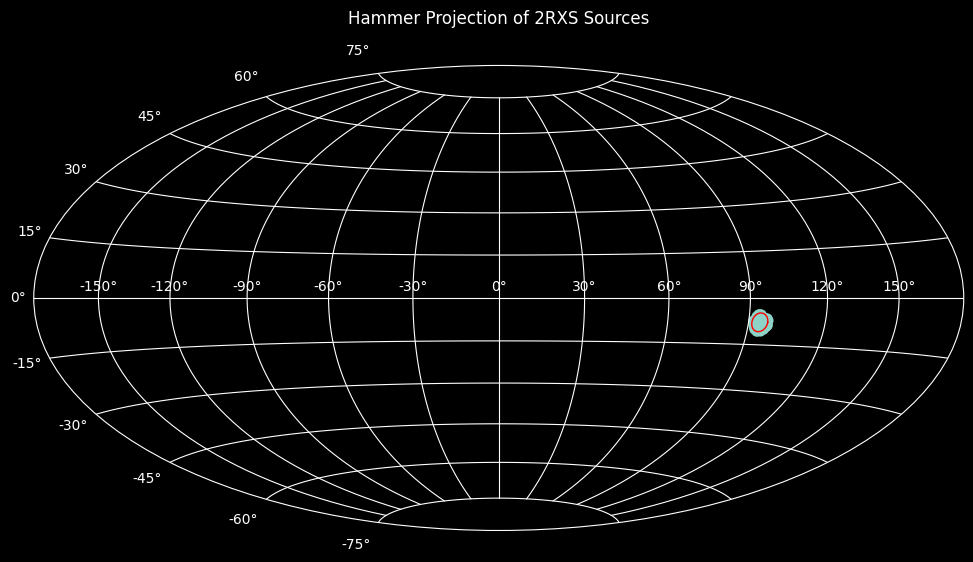

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord


df = pd.read_csv("ROSAT.txt", sep=r"\s+")

import astropy.units as u

coords = SkyCoord(
    ra=df["ra"].to_numpy() * u.deg,
    dec=df["dec"].to_numpy() * u.deg,
    frame="icrs"
)

# 3. Get RA and Dec in degrees
ra_deg = coords.ra.degree
dec_deg = coords.dec.degree

# 4. Convert degrees to radians
ra_rad = np.radians(ra_deg)
dec_rad = np.radians(dec_deg)

# 5. Wrap RA from 0–360 degrees into -180–180 degrees
ra_rad = np.remainder(ra_rad + 2 * np.pi, 2 * np.pi)

ra_rad[ra_rad > np.pi] -= 2 * np.pi

# 6. Reverse RA so it increases toward the left
#    (standard astronomical sky-map convention)

# 7. Make the Hammer projection
fig = plt.figure(figsize=(12, 7))

ax = fig.add_subplot(111, projection="hammer")

# 8. Plot the sources
ax.scatter(
    ra_rad,
    dec_rad,
    s=40
)

# 9. Add grid and title
ax.grid(True)

ax.set_title(
    "Hammer Projection of 2RXS Sources",
    pad=30
)

center_ra_deg = 94.3
center_dec_deg = -7.8
radius_deg = 3

theta = np.linspace(0, 2 * np.pi, 300)

circle_ra_deg = center_ra_deg + radius_deg * np.cos(theta) / np.cos(np.radians(center_dec_deg))
circle_dec_deg = center_dec_deg + radius_deg * np.sin(theta)

circle_ra_plot_deg = (circle_ra_deg + 180) % 360 - 180

circle_ra_rad = np.radians(circle_ra_plot_deg)
circle_dec_rad = np.radians(circle_dec_deg)

ax.plot(circle_ra_rad, circle_dec_rad, color="red", linewidth=1)

plt.show()

In [3]:

import astropy.units as u
from astropy.coordinates import SkyCoord

# 1. Define the centre of the target region
center = SkyCoord(
    ra=94.3 * u.deg,
    dec=-7.8 * u.deg,
    frame="icrs"
)

# 2. Define the search radius
radius = 3 * u.deg

# 3. Calculate angular separation for every ROSAT source
separations = coords.separation(center)

# 4. Select sources within 3 degrees
inside = separations <= radius

# 5. Create a table of sources inside the region
sources_inside = df.loc[inside].copy()

# 6. Add angular distance from the centre
sources_inside["Distance_deg"] = separations[inside].deg

# 7. Sort sources by distance
sources_inside = sources_inside.sort_values(
    by="Distance_deg"
)

# 8. Print results
print("Number of sources inside region:", len(sources_inside))

print("\nSources within 3 degrees of RA=94.3, Dec=-7.8:")
display(sources_inside)

# 9. Save results to a CSV file
sources_inside.to_csv(
    "ROSAT_sources_inside_region.csv",
    index=False
)


Number of sources inside region: 83

Sources within 3 degrees of RA=94.3, Dec=-7.8:


,name,ra,dec,count_rate,count_rate_error,exposure,source_extent,source_extent_prob,source_quality_flag,hardness_ratio_1,hardness_ratio_2,_offset,Distance_deg
2RXS,J061542.4-074811,93.92675,-7.80316,0.0204,0.0082,531.45,0.000,0.00,0,0.000,0.000,22.1885,0.369809
2RXS,J061849.0-075737,94.70447,-7.96036,0.0238,0.0084,528.68,0.218,0.14,0,0.910,1.000,25.8930,0.431551
2RXS,J061542.8-072339,93.92867,-7.39419,0.1510,0.0185,530.11,0.094,0.04,0,0.463,0.221,32.8720,0.547866
2RXS,J061933.1-075424,94.88793,-7.90682,0.0192,0.0081,526.93,0.000,0.00,0,0.028,1.000,35.5278,0.592130
2RXS,J061902.6-072357,94.76125,-7.39930,0.0221,0.0089,525.99,0.137,0.01,0,0.599,-0.923,36.4764,0.607939
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2RXS,J062807.6-084721,97.03190,-8.78927,0.0183,0.0077,526.96,0.000,0.00,0,0.832,-1.000,172.7165,2.878608
2RXS,J062838.7-082855,97.16165,-8.48201,0.0216,0.0087,524.44,0.000,0.00,0,-0.681,-1.000,174.8238,2.913731
2RXS,J061257.8-050344,93.24112,-5.06238,0.0184,0.0080,505.53,0.000,0.00,0,0.427,0.713,175.9699,2.932832
2RXS,J062841.9-065803,97.17473,-6.96771,0.0257,0.0097,515.87,0.396,0.19,0,0.297,-0.421,178.1920,2.969867
